# TTSIDC: truncated Taylor series iterative downward continuation (Zhang et al., 2013)

Classical baseline, no training. For every grid the smoothing parameter σ is chosen with the C-norm
criterion and the number of iterations at the knee of the data-misfit curve, so the method uses no
ground truth. Runs on CPU.

**Evaluation protocol (all notebooks).** The 10 synthetic test grids (32 × 32 nodes, 50 m spacing) are
scaled to [-1, 1] per grid. PSNR, SSIM, relative error (RE) and RMSE are computed on the central 24 × 24
window and reported as mean ± standard deviation (ddof = 0) over the 10 grids. Networks run in full FP32
with deterministic cuDNN (set when `gravdc` is imported, see `gravdc/precision.py`).

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # make the gravdc package importable

import numpy as np
import torch

from gravdc import evaluate, format_summary, load_model, load_test_set, save_result, summarize
from gravdc.plotting import show_reconstruction
from gravdc.table2 import compare

DATA_DIR = "../data/test"
RESULTS_DIR = "../results"
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch", torch.__version__)

device: cuda | torch 2.9.0+cu128


## Data
Observation: the ground-level field continued 100 m upward with the multiscale operator (40 steps of
2.5 m), the same input that the multiscale models receive.

In [2]:
from gravdc import MultiscaleOperator
from gravdc import classical

names, x = load_test_set(DATA_DIR)
A = MultiscaleOperator()  # 40 x 2.5 m = 100 m
y = A(x)
print(len(names), "grids:", names)

10 grids: ['data11.mat', 'data111.mat', 'data211.mat', 'data311.mat', 'data411.mat', 'data511.mat', 'data611.mat', 'data711.mat', 'data811.mat', 'data911.mat']


## Inference

In [3]:
TTSIDC = dict(cell=50, z=100, expand=10, window=3, taylor_down=6, taylor_up=3)

recs = []
for name, f in zip(names, y[:, 0].numpy()):
    sigma = classical.select_sigma_cnorm(f, n=50, sigma_start=1.2, ratio=1.02, iterations=4, **TTSIDC)
    k = classical.select_iterations(f, sigma, max_iter=100, **TTSIDC)
    recs.append(classical.ttsidc(f, sigma=sigma, iterations=k, **TTSIDC))
    print(f"{name:12s} sigma = {sigma:.4f}   iterations = {k}")
x_hat = np.stack(recs)[:, None]

data11.mat   sigma = 1.7139   iterations = 10
data111.mat  sigma = 1.7482   iterations = 10
data211.mat  sigma = 1.6473   iterations = 10
data311.mat  sigma = 1.6803   iterations = 11
data411.mat  sigma = 1.7139   iterations = 10
data511.mat  sigma = 1.6803   iterations = 10
data611.mat  sigma = 1.7482   iterations = 10
data711.mat  sigma = 1.7831   iterations = 10
data811.mat  sigma = 1.7831   iterations = 11
data911.mat  sigma = 1.6803   iterations = 10


## Metrics

In [4]:
per_image = evaluate(x, x_hat)
compare("TTSIDC", summarize(per_image))
save_result("TTSIDC", per_image, names, RESULTS_DIR)

TTSIDC
  metric             this run              Table 2
  PSNR       47.9276 ± 4.5850     47.9276 ± 4.5850  ✓
  SSIM        0.9985 ± 0.0014      0.9985 ± 0.0014  ✓
  RE          0.0135 ± 0.0077      0.0135 ± 0.0077  ✓
  RMSE        0.0094 ± 0.0067      0.0094 ± 0.0067  ✓


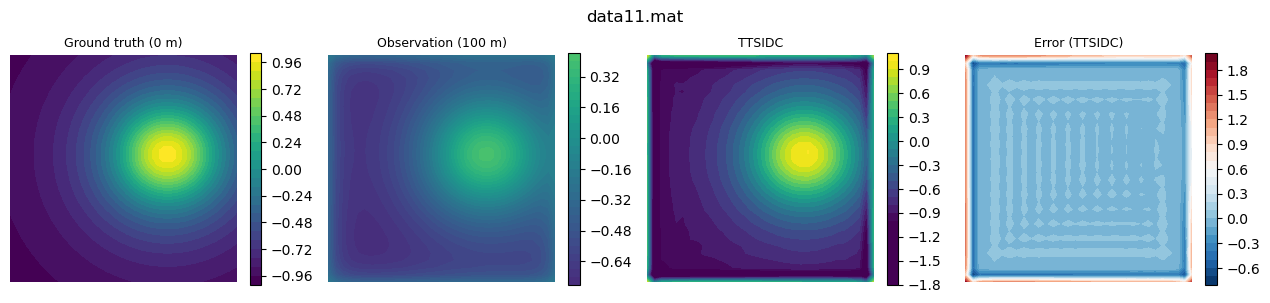

In [5]:
k = 0
show_reconstruction(x[k], y[k], {"TTSIDC": x_hat[k]}, title=names[k])